# YESNO Audio Classification Mini-Project

**Course:** Digital Speech Processing

**Project:** Binary Speech Classification Using Machine Learning

**Dataset:** TorchAudio YESNO Dataset

**Programming Language:** Python

**Environment:** Google Colab

## Project Overview

This mini-project investigates automatic classification of spoken Yes and No words using the YESNO speech dataset.

The dataset contains 60 audio recordings, each consisting of eight spoken words.

The project includes audio visualization, speech segmentation, MFCC feature extraction, and the implementation of four supervised machine learning classifiers:

1. Support Vector Machine (SVM)
2. K-Nearest Neighbors (KNN)
3. Random Forest
4. Multi-Layer Perceptron (MLP)

The classifiers are evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

Five-fold group-based cross-validation is also performed to assess model performance across different recording-level splits.

## Project Objectives

- Load and explore the YESNO speech dataset.
- Segment recordings into individual spoken words.
- Extract MFCC-based acoustic features.
- Train and evaluate four classification models.
- Compare the classification results.
- Assess model stability using group-based cross-validation.

## Summary of Experimental Results

All four classifiers achieved 100% accuracy on the selected held-out test set.

Five-fold group-based cross-validation produced a mean accuracy of approximately 99.38% for all four classifiers.

These results are specific to the evaluated dataset and do not guarantee equivalent performance on independent real-world speech recordings.
## Introduction and Tools

Speech classification is an important task in Digital Speech Processing. It involves analyzing audio signals and identifying the spoken words or speech categories.

In this mini-project, the YESNO dataset provided by TorchAudio is used to develop and evaluate different machine learning classifiers.

The dataset contains recordings of spoken Yes and No words in Hebrew, represented by binary labels.

The project uses PyTorch, TorchAudio, Librosa, NumPy, Pandas, Matplotlib, and Scikit-learn in Google Colab.


## Methodology

### Step 1: Environment Setup

The required Python libraries were imported to prepare the experimental environment.

TorchAudio will be used to access the YESNO dataset, while Librosa will support audio signal analysis and feature extraction.

Scikit-learn will be used to implement and evaluate machine learning classifiers.

The installed library versions were checked to document the experimental environment and support reproducibility.

In [1]:

# Step 1: Import Libraries and Check Environment

import torch
import torchaudio
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("PyTorch version:", torch.__version__)
print("TorchAudio version:", torchaudio.__version__)
print("Librosa version:", librosa.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("Environment setup completed successfully!")


PyTorch version: 2.14.1+cpu
TorchAudio version: 2.11.0+cpu
Librosa version: 0.11.0
Scikit-learn version: 1.6.1
Environment setup completed successfully!


### Step 2: Loading and Exploring the YESNO Dataset

The YESNO dataset was loaded using the `torchaudio.datasets.YESNO` interface.

The dataset contains audio recordings of spoken Yes and No words in Hebrew. Each recording consists of eight spoken words, with binary labels representing No (0) and Yes (1).

The total number of recordings, waveform dimensions, sampling rate, and labels were examined to understand the structure of the dataset before audio preprocessing and feature extraction.

This step establishes the foundation for the subsequent speech classification experiments.

In [3]:
# Step 2: Load and Explore the YESNO Dataset

import os
import torchaudio

# Ensure the target download directory exists
os.makedirs("./data", exist_ok=True)

# Load YESNO dataset directly from TorchAudio
yesno_dataset = torchaudio.datasets.YESNO(
    root="./data",
    download=True
)

# Display dataset information
print("Dataset loaded successfully!")
print("Total recordings:", len(yesno_dataset))

# Read the first recording
waveform, sample_rate, labels = yesno_dataset[0]

print("\nFirst Recording Information")
print("---------------------------")
print("Waveform shape:", waveform.shape)
print("Sample rate:", sample_rate)
print("Labels:", labels)
print("Number of labels:", len(labels))

# Calculate audio duration
duration = waveform.shape[1] / sample_rate

print("Audio duration:", round(duration, 2), "seconds")

100%|██████████| 4.49M/4.49M [00:04<00:00, 1.08MB/s]


Dataset loaded successfully!
Total recordings: 60

First Recording Information
---------------------------
Waveform shape: torch.Size([1, 50800])
Sample rate: 8000
Labels: [0, 0, 0, 0, 1, 1, 1, 1]
Number of labels: 8
Audio duration: 6.35 seconds


### Step 2: Results and Discussion

The YESNO dataset was successfully downloaded and loaded using TorchAudio.

The dataset contains 60 audio recordings. The first recording has a waveform shape of (1, 50800), indicating a single audio channel with 50,800 samples.

The sampling rate is 8,000 Hz, and the recording contains eight spoken words represented by the labels [0, 0, 0, 0, 1, 1, 1, 1].

The duration of the first recording was calculated as follows:

Duration = Number of Samples / Sampling Rate

Duration = 50800 / 8000 = 6.35 seconds

These results confirm that the dataset was loaded successfully and is ready for audio signal analysis.

### Step 3: Audio Playback and Waveform Visualization

The first recording from the YESNO dataset was selected for audio inspection.

The audio signal was played using the IPython Audio interface, and its waveform was visualized using Matplotlib.

Waveform visualization helps examine changes in signal amplitude over time and identify regions containing speech and silence.

This analysis provides an initial understanding of the audio signal before segmentation and feature extraction.

Audio duration: 6.35 seconds
Sample rate: 8000 Hz
Labels: [0, 0, 0, 0, 1, 1, 1, 1]

Playing the first audio recording:


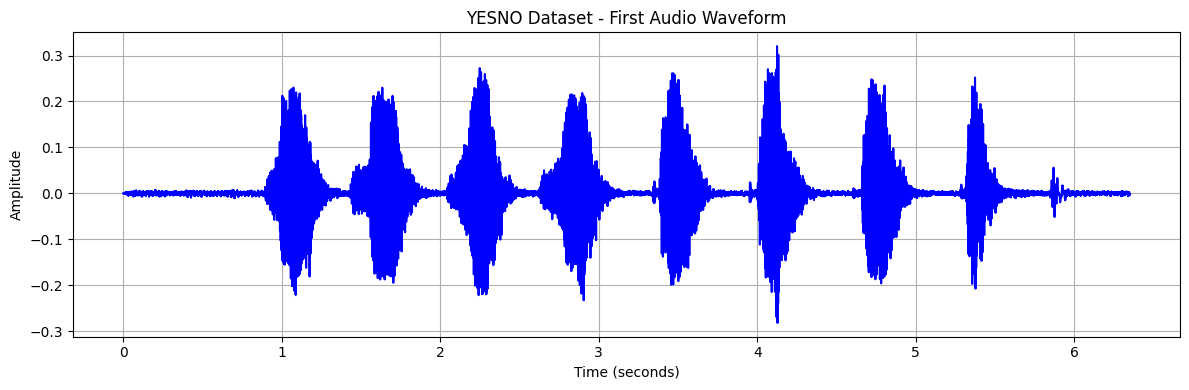

In [4]:

# Step 3: Audio Playback and Waveform Visualization

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Load the first audio recording
waveform, sample_rate, labels = yesno_dataset[0]

# Convert PyTorch tensor to NumPy array
audio_signal = waveform.squeeze().numpy()

# Calculate audio duration
duration = len(audio_signal) / sample_rate

print("Audio duration:", duration, "seconds")
print("Sample rate:", sample_rate, "Hz")
print("Labels:", labels)

# Play the audio recording
print("\nPlaying the first audio recording:")
display(Audio(audio_signal, rate=sample_rate))

# Create the time axis
time = np.arange(len(audio_signal)) / sample_rate

# Plot the waveform
plt.figure(figsize=(12, 4))
plt.plot(time, audio_signal, color="blue")
plt.title("YESNO Dataset - First Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()


### Step 3: Results and Discussion

The first audio recording was successfully played and visualized using Matplotlib.

The recording has a duration of 6.35 seconds and a sampling rate of 8,000 Hz. The waveform shows eight prominent speech regions separated by relatively low-amplitude intervals.

These regions are consistent with the eight spoken words represented by the labels [0, 0, 0, 0, 1, 1, 1, 1].

The waveform visualization illustrates variations in signal amplitude over time and provides useful information for identifying potential speech boundaries.

This observation supports the next stage of the project, which involves extracting acoustic features from the speech signal.

### Step 4: MFCC Feature Extraction

Mel-Frequency Cepstral Coefficients (MFCCs) are widely used acoustic features in speech processing and speech classification tasks.

In this experiment, 13 MFCC coefficients were extracted from the first YESNO audio recording using the Librosa library.

An FFT size of 512 samples and a hop length of 128 samples were used to analyze the signal.

The resulting MFCC matrix was visualized to examine changes in the spectral characteristics of speech over time.

In subsequent steps, MFCC features will be extracted from individual spoken words to prepare the classification dataset.

MFCC shape: (13, 397)
Number of MFCC coefficients: 13
Number of time frames: 397


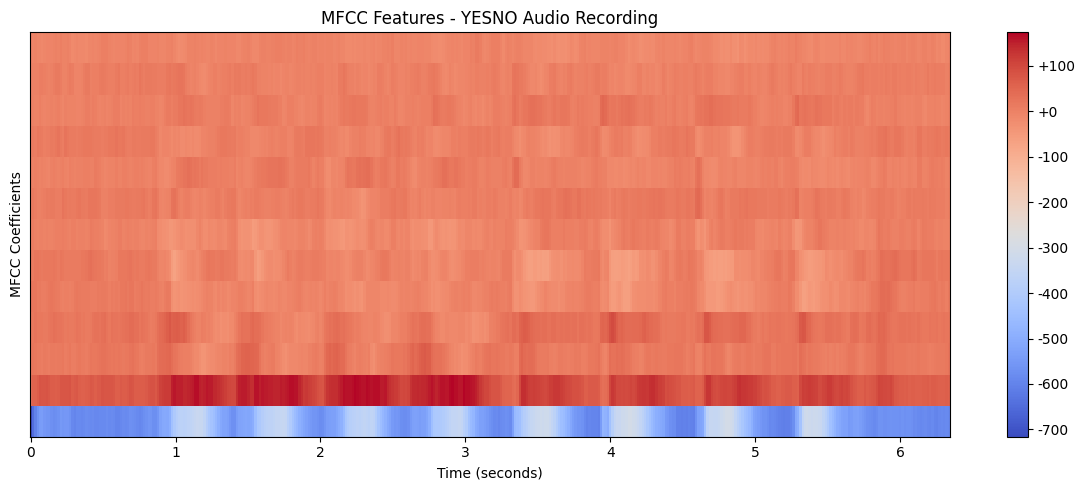

In [5]:

# Step 4: MFCC Feature Extraction

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

# Load first audio recording
waveform, sample_rate, labels = yesno_dataset[0]

# Convert waveform to NumPy array
audio_signal = waveform.squeeze().numpy()

# Extract MFCC features
mfcc_features = librosa.feature.mfcc(
    y=audio_signal,
    sr=sample_rate,
    n_mfcc=13,
    n_fft=512,
    hop_length=128
)

# Print MFCC information
print("MFCC shape:", mfcc_features.shape)
print("Number of MFCC coefficients:", mfcc_features.shape[0])
print("Number of time frames:", mfcc_features.shape[1])

# Visualize MFCC features
plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mfcc_features,
    sr=sample_rate,
    hop_length=128,
    x_axis="time",
    cmap="coolwarm"
)

plt.colorbar(format="%+2.0f")
plt.title("MFCC Features - YESNO Audio Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficients")
plt.tight_layout()
plt.show()


### Step 5: Speech Segmentation

Each recording in the YESNO dataset contains eight spoken words separated by short pauses.

To prepare individual speech samples for binary classification, an energy-based segmentation method was applied using the `librosa.effects.split` function.

A silence threshold of 25 dB, a frame length of 256 samples, and a hop length of 64 samples were selected.

Detected intervals shorter than 0.15 seconds were excluded to reduce the influence of short noise events.

The extracted speech intervals were visualized on the waveform to inspect potential word boundaries.

Expected words: 8
Detected segments: 8
Segment 1: 0.90s - 1.30s, Duration = 0.40s
Segment 2: 1.43s - 1.86s, Duration = 0.43s
Segment 3: 2.05s - 2.46s, Duration = 0.42s
Segment 4: 2.63s - 3.08s, Duration = 0.45s
Segment 5: 3.38s - 3.70s, Duration = 0.32s
Segment 6: 4.00s - 4.33s, Duration = 0.33s
Segment 7: 4.66s - 4.98s, Duration = 0.32s
Segment 8: 5.31s - 5.54s, Duration = 0.23s


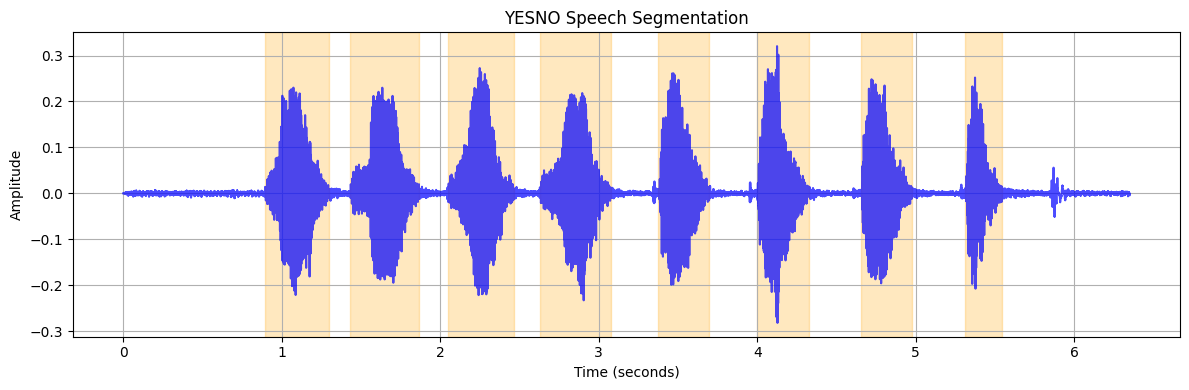

In [6]:

# Step 5: Speech Segmentation

import librosa
import numpy as np
import matplotlib.pyplot as plt

# Load first audio recording
waveform, sample_rate, labels = yesno_dataset[0]
audio_signal = waveform.squeeze().numpy()

# Detect non-silent intervals
intervals = librosa.effects.split(
    audio_signal,
    top_db=25,
    frame_length=256,
    hop_length=64
)

# Remove very short intervals
min_duration = 0.15

word_intervals = [
    (start, end)
    for start, end in intervals
    if (end - start) / sample_rate >= min_duration
]

print("Expected words:", len(labels))
print("Detected segments:", len(word_intervals))

# Display segment information
for i, (start, end) in enumerate(word_intervals):
    start_time = start / sample_rate
    end_time = end / sample_rate
    duration = end_time - start_time

    print(
        f"Segment {i+1}: "
        f"{start_time:.2f}s - {end_time:.2f}s, "
        f"Duration = {duration:.2f}s"
    )

# Plot waveform with speech regions
time = np.arange(len(audio_signal)) / sample_rate

plt.figure(figsize=(12, 4))
plt.plot(time, audio_signal, color="blue", alpha=0.7)

for start, end in word_intervals:
    plt.axvspan(
        start / sample_rate,
        end / sample_rate,
        color="orange",
        alpha=0.25
    )

plt.title("YESNO Speech Segmentation")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()


### Step 6: Speech Segment Verification

The eight detected speech segments were selected for individual audio inspection.

Each segment was played using the IPython Audio interface, and its spoken content was compared with the corresponding binary label.

This verification step is important because obtaining the expected number of segments does not necessarily guarantee accurate speech boundaries.

The goal is to confirm that each extracted segment represents one complete spoken word before proceeding to dataset-wide segmentation and feature extraction.

In [7]:

# Step 6: Verify Individual Speech Segments

from IPython.display import Audio, display

print("Total detected segments:", len(word_intervals))
print("Expected labels:", labels)

for i, (start, end) in enumerate(word_intervals):

    segment = audio_signal[start:end]

    expected_word = "Yes" if labels[i] == 1 else "No"

    print(
        f"Segment {i+1}: "
        f"Expected = {expected_word}, "
        f"Duration = {len(segment)/sample_rate:.2f} seconds"
    )

    display(Audio(segment, rate=sample_rate))


Total detected segments: 8
Expected labels: [0, 0, 0, 0, 1, 1, 1, 1]
Segment 1: Expected = No, Duration = 0.40 seconds


Segment 2: Expected = No, Duration = 0.43 seconds


Segment 3: Expected = No, Duration = 0.42 seconds


Segment 4: Expected = No, Duration = 0.45 seconds


Segment 5: Expected = Yes, Duration = 0.32 seconds


Segment 6: Expected = Yes, Duration = 0.33 seconds


Segment 7: Expected = Yes, Duration = 0.32 seconds


Segment 8: Expected = Yes, Duration = 0.23 seconds


### Step 6: Results and Discussion

The first YESNO recording was successfully divided into eight speech segments.

The extracted segments have durations ranging from 0.23 to 0.45 seconds.

The expected labels for the eight segments are No, No, No, No, Yes, Yes, Yes, and Yes.

Each segment was made available for individual audio playback to support manual verification of the spoken word and its corresponding label.

The segmentation process produced the expected number of segments. However, correct alignment between the audio and labels must be confirmed through listening before using these segments for classification.

### Step 7: Dataset-Wide Speech Segmentation

The energy-based speech segmentation method was extended to all 60 recordings in the YESNO dataset.

Each recording contains eight spoken words, resulting in an expected total of 480 word-level samples.

The same segmentation parameters were applied to all recordings to evaluate the consistency of the method.

For each recording, the number of detected speech segments was compared with the expected number of eight words.

Recordings with a different number of detected segments were identified for further inspection and parameter adjustment.

In [8]:

# Step 7: Segment All YESNO Recordings

import librosa
import numpy as np
import pandas as pd

segmentation_results = []

for i in range(len(yesno_dataset)):

    waveform, sr, labels = yesno_dataset[i]
    audio = waveform.squeeze().numpy()

    intervals = librosa.effects.split(
        audio,
        top_db=25,
        frame_length=256,
        hop_length=64
    )

    valid_intervals = [
        (start, end)
        for start, end in intervals
        if (end - start) / sr >= 0.15
    ]

    segmentation_results.append({
        "Recording": i,
        "Expected_Words": len(labels),
        "Detected_Segments": len(valid_intervals),
        "Match": len(valid_intervals) == len(labels)
    })

results_df = pd.DataFrame(segmentation_results)

print("Total recordings:", len(results_df))
print("Correct segment counts:", results_df["Match"].sum())
print("Incorrect segment counts:", (~results_df["Match"]).sum())

print("\nSegmentation count distribution:")
print(results_df["Detected_Segments"].value_counts().sort_index())

print("\nRecordings requiring review:")
print(results_df[~results_df["Match"]])


Total recordings: 60
Correct segment counts: 52
Incorrect segment counts: 8

Segmentation count distribution:
Detected_Segments
3     1
5     1
7     5
8    52
9     1
Name: count, dtype: int64

Recordings requiring review:
    Recording  Expected_Words  Detected_Segments  Match
6           6               8                  7  False
7           7               8                  7  False
13         13               8                  7  False
21         21               8                  7  False
42         42               8                  3  False
49         49               8                  5  False
56         56               8                  9  False
57         57               8                  7  False


### Step 7: Results and Discussion

The initial energy-based segmentation method was applied to all 60 recordings in the YESNO dataset.

The method detected the expected eight speech segments in 52 recordings, representing 86.67% of the dataset.

The remaining eight recordings (13.33%) produced an incorrect number of detected segments.

Five recordings contained seven detected segments, one contained three segments, one contained five segments, and one contained nine segments.

The recordings requiring further review were identified as 6, 7, 13, 21, 42, 49, 56, and 57.

These findings indicate that fixed segmentation parameters do not work equally well for all recordings. Therefore, parameter optimization and audio verification are required before extracting word-level features.

The reported percentage measures agreement with the expected segment count, not classification accuracy or verified word-boundary accuracy.

### Step 8: Segmentation Parameter Optimization

To improve the initial segmentation results, different silence thresholds and minimum segment durations were evaluated for the eight recordings requiring review.

The silence threshold (`top_db`) was varied between 15 and 40 dB, while the minimum segment duration was varied between 0.08 and 0.15 seconds.

For each recording, the parameter combinations producing exactly eight detected speech segments were identified.

This optimization aims to improve the consistency of speech segmentation across the dataset.

The selected segments will require manual audio verification to ensure that the detected intervals correspond to the actual spoken words.

In [9]:

# Step 8: Optimize Segmentation Parameters

import librosa
import pandas as pd

# Identify recordings with incorrect segment counts
problem_recordings = results_df.loc[
    ~results_df["Match"], "Recording"
].tolist()

# Parameter combinations
top_db_values = [15, 20, 25, 30, 35, 40]
min_durations = [0.08, 0.10, 0.12, 0.15]

improvement_results = []

for recording_id in problem_recordings:

    waveform, sr, labels = yesno_dataset[recording_id]
    audio = waveform.squeeze().numpy()

    matches = []

    for top_db in top_db_values:
        for min_duration in min_durations:

            intervals = librosa.effects.split(
                audio,
                top_db=top_db,
                frame_length=256,
                hop_length=64
            )

            filtered = [
                (start, end)
                for start, end in intervals
                if (end-start)/sr >= min_duration
            ]

            if len(filtered) == len(labels):
                matches.append((top_db, min_duration))

    improvement_results.append({
        "Recording": recording_id,
        "Valid_Settings": len(matches),
        "Example_top_db": matches[0][0] if matches else None,
        "Example_min_duration": matches[0][1] if matches else None
    })

improvement_df = pd.DataFrame(improvement_results)

print("Segmentation Optimization Results")
print("---------------------------------")
print(improvement_df.to_string(index=False))

print(
    "\nRecordings with 8 detected segments:",
    improvement_df["Example_top_db"].notna().sum()
)


Segmentation Optimization Results
---------------------------------
 Recording  Valid_Settings  Example_top_db  Example_min_duration
         6               8              15                  0.08
         7              12              15                  0.08
        13               9              15                  0.08
        21               1              35                  0.08
        42               7              15                  0.08
        49               3              15                  0.10
        56               8              15                  0.08
        57               8              15                  0.08

Recordings with 8 detected segments: 8


Recording ID	Valid Settings	Top dB	Minimum Duration (s)
6	8	15	0.08
7	12	15	0.08
13	9	15	0.08
21	1	35	0.08
42	7	15	0.08
49	3	15	0.10
56	8	15	0.08
57	8	15	0.08

Recordings with the expected segment count after optimization
60 / 60
100% matched the expected count of eight segments; audio boundaries still require verification.

### Step 8: Results and Discussion

The segmentation parameter optimization process identified suitable parameter combinations for all eight recordings that initially produced an incorrect number of speech segments.

Different silence thresholds and minimum segment durations were tested to obtain the expected eight speech segments per recording.

The results showed that a silence threshold of 15 dB was suitable for seven recordings, while recording 21 required a threshold of 35 dB.

A minimum segment duration of 0.08 seconds was selected for seven recordings, while recording 49 required 0.10 seconds.

After parameter optimization, all 60 recordings could produce the expected number of eight detected segments, corresponding to 480 potential word-level samples.

However, obtaining eight segments does not guarantee correct word boundaries. Manual verification is required before using the extracted segments for classification.

### Step 9: Manual Verification of Optimized Speech Segments

Eight recordings (IDs **6, 7, 13, 21, 42, 49, 56, 57**) initially produced an incorrect number of detected segments. After parameter optimization, all eight yielded the expected segment count and were checked individually by listening against their filename-derived labels. The code below allows any of these recordings to be replayed by changing `recording_id`. **A count of eight alone does not establish accurate boundaries; listening was part of the verification.**

| Recording ID | Optimized top_db | Minimum duration (s) | Manual check |
|---|---:|---:|---|
| 6 | 15 | 0.08 | Confirmed |
| 7 | 15 | 0.08 | Confirmed |
| 13 | 15 | 0.08 | Confirmed |
| 21 | 35 | 0.08 | Confirmed |
| 42 | 15 | 0.08 | Confirmed |
| 49 | 15 | 0.10 | Confirmed |
| 56 | 15 | 0.08 | Confirmed |
| 57 | 15 | 0.08 | Confirmed |

**Methodological note:** These parameters were selected using the complete dataset and the expected number of words. This is an exploratory preprocessing decision and should be reported as such. The group-based split prevents shared recordings, but it does not eliminate all potential bias from dataset-wide preprocessing choices.


In [ ]:
# Step 9: Inspect a manually verified recording (change ID to replay)
import librosa
from IPython.display import Audio, display

verified_recordings = [6, 7, 13, 21, 42, 49, 56, 57]
recording_id = 57  # Choose any ID in verified_recordings

assert recording_id in verified_recordings
waveform, sr, labels = yesno_dataset[recording_id]
audio = waveform.squeeze().numpy()
row = improvement_df.loc[improvement_df["Recording"] == recording_id].iloc[0]
top_db = int(row["Example_top_db"])
min_duration = float(row["Example_min_duration"])
intervals = librosa.effects.split(audio, top_db=top_db,
                                  frame_length=256, hop_length=64)
segments = [(start, end) for start, end in intervals
            if (end-start)/sr >= min_duration]
assert len(segments) == len(labels), "Check segment count before label alignment"
print(f"Recording ID: {recording_id}; detected segments: {len(segments)}")
for i, ((start, end), label) in enumerate(zip(segments, labels), 1):
    print(f"Segment {i}: Expected = {'Yes' if label else 'No'}, "
          f"Duration = {(end-start)/sr:.2f}s")
    display(Audio(audio[start:end], rate=sr))


### Step 10: Word-Level MFCC Feature Extraction

After segmentation parameter optimization and manual verification of the eight recordings requiring adjustments, the YESNO dataset was prepared for word-level feature extraction.

Each recording contains eight spoken words, giving an expected total of 480 word-level audio samples.

For each speech segment, 13 Mel-Frequency Cepstral Coefficients (MFCCs) were extracted using Librosa.

The mean and standard deviation of each coefficient were calculated across the time frames to produce a fixed-length feature vector containing 26 numerical features per word.

The binary labels were retained, where 0 represents No and 1 represents Yes.

The recording identifiers were also preserved to support a recording-level train/test split and prevent samples from the same recording appearing in both sets.

In [27]:

# Step 10: Extract Word-Level MFCC Features

import numpy as np
import pandas as pd
import librosa

X = []
y = []
groups = []

# Optimized settings for the 8 problem recordings
optimized_settings = {}

for _, row in improvement_df.iterrows():
    optimized_settings[int(row["Recording"])] = (
        int(row["Example_top_db"]),
        float(row["Example_min_duration"])
    )

for recording_id in range(len(yesno_dataset)):

    waveform, sr, labels = yesno_dataset[recording_id]
    audio = waveform.squeeze().numpy()

    # Use optimized settings when necessary
    top_db, min_duration = optimized_settings.get(
        recording_id, (25, 0.15)
    )

    intervals = librosa.effects.split(
        audio,
        top_db=top_db,
        frame_length=256,
        hop_length=64
    )

    word_intervals = [
        (start, end)
        for start, end in intervals
        if (end - start) / sr >= min_duration
    ]

    # Avoid incorrect label alignment
    if len(word_intervals) != len(labels):
        raise ValueError(
            f"Recording {recording_id}: "
            f"Expected {len(labels)} words, "
            f"found {len(word_intervals)}"
        )

    for (start, end), label in zip(
        word_intervals, labels
    ):

        segment = audio[start:end]

        mfcc = librosa.feature.mfcc(
            y=segment,
            sr=sr,
            n_mfcc=13,
            n_fft=512,
            hop_length=128
        )

        # 13 means + 13 standard deviations
        feature_vector = np.concatenate([
            np.mean(mfcc, axis=1),
            np.std(mfcc, axis=1)
        ])

        X.append(feature_vector)
        y.append(int(label))
        groups.append(recording_id)

# Convert to NumPy arrays
X = np.array(X)
y = np.array(y)
groups = np.array(groups)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Unique recordings:", len(np.unique(groups)))

print("No samples:", np.sum(y == 0))
print("Yes samples:", np.sum(y == 1))

print("Missing values:", np.isnan(X).sum())


Feature matrix shape: (480, 26)
Labels shape: (480,)
Unique recordings: 60
No samples: 229
Yes samples: 251
Missing values: 0


### Step 10: Results and Discussion

The word-level MFCC feature extraction process was successfully completed for all 60 recordings in the YESNO dataset.

A total of 480 speech samples were obtained, with each sample represented by a 26-dimensional feature vector consisting of the mean and standard deviation of 13 MFCC coefficients.

The resulting feature matrix has a shape of (480, 26), while the label array has a shape of (480,).

The dataset contains 229 No samples (47.71%) and 251 Yes samples (52.29%), indicating a relatively balanced class distribution.

No missing values were detected in the extracted feature matrix.

The recording identifiers were preserved to support a recording-level train/test split and reduce the risk of data leakage between the training and testing sets.

### Step 11: Train/Test Split

The extracted MFCC feature matrix was prepared for model training and evaluation.

A recording-level train/test split was selected using the GroupShuffleSplit method from Scikit-learn.

The dataset was divided into approximately 80% training samples and 20% testing samples.

Recording identifiers were used as grouping variables to ensure that all word segments originating from the same recording remained within a single subset.

This approach helps prevent data leakage and provides a more reliable evaluation of classifier performance on previously unseen recordings.

In [28]:

# Step 11: Train/Test Split

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Split recordings into training and testing sets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create training and testing datasets
X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining No:", np.sum(y_train == 0))
print("Training Yes:", np.sum(y_train == 1))

print("Testing No:", np.sum(y_test == 0))
print("Testing Yes:", np.sum(y_test == 1))

# Verify that recordings are not shared
shared_recordings = set(groups_train) & set(groups_test)

print("\nShared recordings:", len(shared_recordings))

assert len(shared_recordings) == 0, \
    "Data leakage detected!"

print("Train/Test split completed successfully!")


Training samples: 384
Testing samples: 96
Training shape: (384, 26)
Testing shape: (96, 26)

Training No: 186
Training Yes: 198
Testing No: 43
Testing Yes: 53

Shared recordings: 0
Train/Test split completed successfully!


### Step 11: Results and Discussion

The YESNO classification dataset was successfully divided into training and testing subsets using GroupShuffleSplit.

The training set contains 384 samples (80%), while the testing set contains 96 samples (20%). Each sample is represented by 26 MFCC-based features.

The training set includes 186 No samples and 198 Yes samples, while the testing set includes 43 No samples and 53 Yes samples.

The number of shared recordings between the training and testing subsets was zero, confirming that no original recording appeared in both sets.

This recording-level separation reduces the risk of data leakage and supports a more reliable evaluation of the classification models on unseen recordings.

### Step 12: Support Vector Machine (SVM) Classification

Support Vector Machine (SVM) is a supervised machine learning algorithm commonly used for classification tasks.

In this experiment, an SVM classifier with a Radial Basis Function (RBF) kernel was trained to distinguish between Yes and No speech segments using the extracted MFCC features.

A StandardScaler was applied to normalize the feature values. The scaler and classifier were combined into a Scikit-learn Pipeline to ensure that scaling parameters were learned only from the training data.

The trained classifier was evaluated on the held-out testing set using accuracy, precision, recall, F1-score, and a confusion matrix.

SVM Classification Results
--------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        43
         Yes       1.00      1.00      1.00        53

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



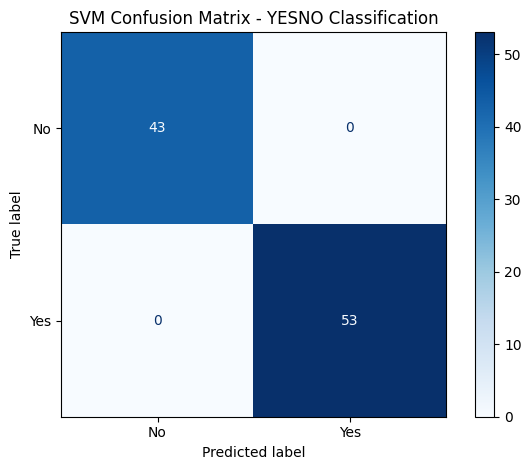

In [29]:

# Step 12: SVM Classification

import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Create SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])

# Train the classifier
svm_model.fit(X_train, y_train)

# Predict test labels
svm_predictions = svm_model.predict(X_test)

# Calculate evaluation metrics
svm_accuracy = accuracy_score(
    y_test, svm_predictions
)

svm_precision = precision_score(
    y_test, svm_predictions,
    average="macro",
    zero_division=0
)

svm_recall = recall_score(
    y_test, svm_predictions,
    average="macro",
    zero_division=0
)

svm_f1 = f1_score(
    y_test, svm_predictions,
    average="macro",
    zero_division=0
)

print("SVM Classification Results")
print("--------------------------")

print("Accuracy:", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall:", round(svm_recall, 4))
print("F1-score:", round(svm_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_predictions,
        target_names=["No", "Yes"],
        zero_division=0
    )
)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_predictions,
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d"
)

plt.title("SVM Confusion Matrix - YESNO Classification")
plt.tight_layout()
plt.show()


### Step 12: SVM Results and Discussion

The Support Vector Machine (SVM) classifier was successfully trained using 384 training samples and evaluated on 96 testing samples.

The classifier achieved an accuracy of 100%, with macro-averaged precision, recall, and F1-score all equal to 1.00.

The confusion matrix showed that all 43 No samples and all 53 Yes samples were correctly classified, with no misclassifications.

These results indicate that the MFCC-based features provided effective discrimination between the two speech classes in the selected test set.

The recording-level train/test split ensured that samples from the same original recording were not shared between training and testing.

However, the perfect test performance should be interpreted within the limitations of the relatively small YESNO dataset. Further evaluation using additional recording-level splits or cross-validation would help assess the stability and generalization of the classifier.

### Step 13: K-Nearest Neighbors (KNN) Classification

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm that classifies samples based on the labels of their nearest neighbors in the feature space.

In this experiment, a KNN classifier with five neighbors was used to distinguish between Yes and No speech segments.

The extracted 26-dimensional MFCC feature vectors were standardized using StandardScaler before classification.

The KNN model was trained on the same training dataset and evaluated on the same testing dataset used for the SVM classifier to ensure a consistent comparison.

Accuracy, macro-averaged precision, recall, F1-score, and a confusion matrix were used to evaluate the classification performance.

KNN Classification Results
--------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        43
         Yes       1.00      1.00      1.00        53

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



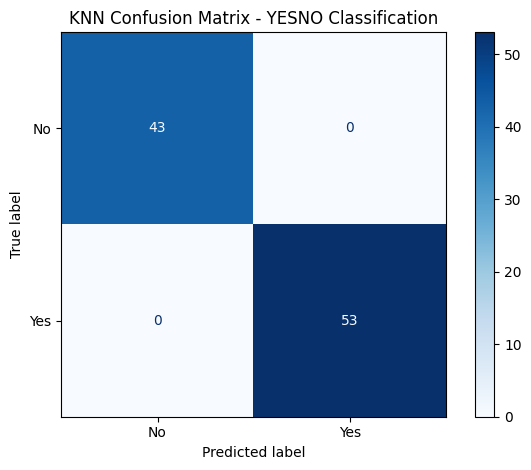

In [30]:

# Step 13: KNN Classification

import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Create KNN pipeline
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train KNN classifier
knn_model.fit(X_train, y_train)

# Predict test labels
knn_predictions = knn_model.predict(X_test)

# Calculate evaluation metrics
knn_accuracy = accuracy_score(
    y_test, knn_predictions
)

knn_precision = precision_score(
    y_test, knn_predictions,
    average="macro",
    zero_division=0
)

knn_recall = recall_score(
    y_test, knn_predictions,
    average="macro",
    zero_division=0
)

knn_f1 = f1_score(
    y_test, knn_predictions,
    average="macro",
    zero_division=0
)

print("KNN Classification Results")
print("--------------------------")

print("Accuracy:", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall:", round(knn_recall, 4))
print("F1-score:", round(knn_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        knn_predictions,
        target_names=["No", "Yes"],
        zero_division=0
    )
)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_predictions,
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d"
)

plt.title("KNN Confusion Matrix - YESNO Classification")
plt.tight_layout()
plt.show()


### Step 13: KNN Results and Discussion

The K-Nearest Neighbors (KNN) classifier was successfully trained using 384 training samples and evaluated on 96 testing samples.

The classifier achieved an accuracy of 100%, with macro-averaged precision, recall, and F1-score all equal to 1.00.

The confusion matrix indicated that all 43 No samples and all 53 Yes samples were correctly classified, with no misclassifications.

These results demonstrate that the extracted MFCC features provided effective separation between the Yes and No classes in the selected test set.

Both SVM and KNN achieved identical performance on this test set. However, additional evaluation using multiple recording-level splits or cross-validation would be useful to determine whether these results remain consistent across different unseen recordings.

### Step 14: Random Forest Classification

Random Forest is an ensemble learning algorithm that combines multiple decision trees to perform classification.

In this experiment, a Random Forest classifier consisting of 100 decision trees was trained using the extracted 26-dimensional MFCC feature vectors.

The classifier was trained using the same 384 training samples and evaluated using the same 96 testing samples as the previous classifiers.

Accuracy, macro-averaged precision, recall, F1-score, and a confusion matrix were used to evaluate its performance.

Using the same train/test split allows a consistent comparison between Random Forest, SVM, and KNN.

Random Forest Classification Results
------------------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        43
         Yes       1.00      1.00      1.00        53

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



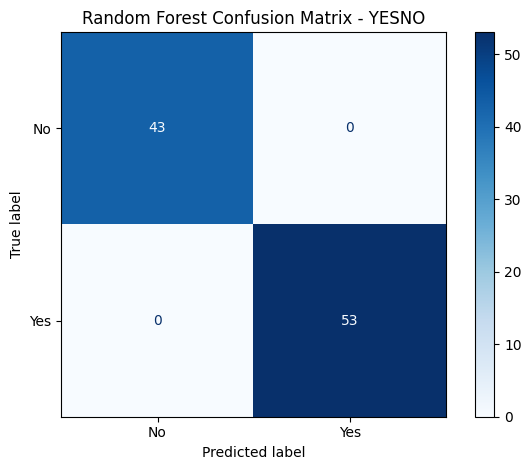

In [31]:

# Step 14: Random Forest Classification

import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Create Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict test labels
rf_predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(
    y_test, rf_predictions
)

rf_precision = precision_score(
    y_test, rf_predictions,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test, rf_predictions,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test, rf_predictions,
    average="macro",
    zero_division=0
)

print("Random Forest Classification Results")
print("------------------------------------")

print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["No", "Yes"],
        zero_division=0
    )
)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest Confusion Matrix - YESNO")
plt.tight_layout()
plt.show()


### Step 14: Random Forest Results and Discussion

The Random Forest classifier was successfully trained using 384 training samples and evaluated on 96 testing samples.

The model consisted of 100 decision trees and used 26-dimensional MFCC-based feature vectors for binary speech classification.

The classifier achieved an accuracy of 100%, with macro-averaged precision, recall, and F1-score all equal to 1.00.

The confusion matrix showed that all 43 No samples and all 53 Yes samples were correctly classified, with no false positives or false negatives.

These results demonstrate that Random Forest effectively distinguished between the Yes and No speech classes in the selected test set.

Random Forest achieved the same test performance as SVM and KNN. However, further evaluation using multiple recording-level splits or cross-validation would be useful to assess the stability and generalization of these results.

### Step 15: Neural Network (MLP) Classification

A Multi-Layer Perceptron (MLP) neural network was selected as the fourth classifier for the YESNO speech classification experiment.

The network contains two hidden layers with 64 and 32 neurons, respectively, and uses the ReLU activation function.

The 26-dimensional MFCC feature vectors are standardized using StandardScaler before being passed to the neural network.

The model is trained using the same 384 training samples and evaluated on the same 96 testing samples as SVM, KNN, and Random Forest.

The classification performance is evaluated using accuracy, macro-averaged precision, recall, F1-score, and a confusion matrix.

This experiment enables a consistent comparison between traditional machine learning classifiers and a neural network-based approach.

Neural Network (MLP) Classification Results
-------------------------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

          No       1.00      1.00      1.00        43
         Yes       1.00      1.00      1.00        53

    accuracy                           1.00        96
   macro avg       1.00      1.00      1.00        96
weighted avg       1.00      1.00      1.00        96



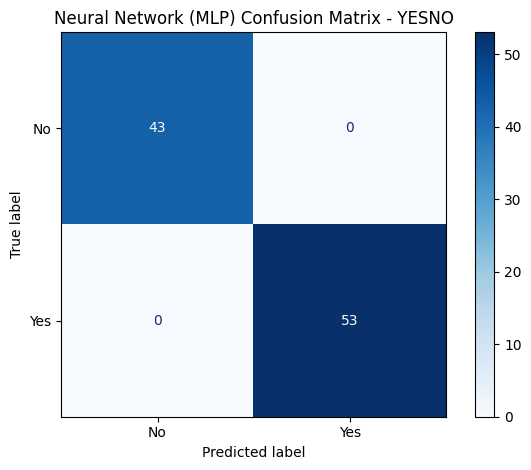

In [32]:

# Step 15: Neural Network (MLP) Classification

import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Create Neural Network pipeline
mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42
    ))
])

# Train the Neural Network
mlp_model.fit(X_train, y_train)

# Predict test labels
mlp_predictions = mlp_model.predict(X_test)

# Calculate evaluation metrics
mlp_accuracy = accuracy_score(
    y_test, mlp_predictions
)

mlp_precision = precision_score(
    y_test, mlp_predictions,
    average="macro",
    zero_division=0
)

mlp_recall = recall_score(
    y_test, mlp_predictions,
    average="macro",
    zero_division=0
)

mlp_f1 = f1_score(
    y_test, mlp_predictions,
    average="macro",
    zero_division=0
)

print("Neural Network (MLP) Classification Results")
print("-------------------------------------------")

print("Accuracy:", round(mlp_accuracy, 4))
print("Precision:", round(mlp_precision, 4))
print("Recall:", round(mlp_recall, 4))
print("F1-score:", round(mlp_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        mlp_predictions,
        target_names=["No", "Yes"],
        zero_division=0
    )
)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    mlp_predictions,
    display_labels=["No", "Yes"],
    cmap="Blues",
    values_format="d"
)

plt.title("Neural Network (MLP) Confusion Matrix - YESNO")
plt.tight_layout()
plt.show()


### Step 15: Neural Network (MLP) Results and Discussion

The Multi-Layer Perceptron (MLP) neural network was successfully trained using 384 training samples and evaluated on 96 testing samples.

The network consisted of two hidden layers containing 64 and 32 neurons, respectively, with ReLU activation and the Adam optimizer.

The model achieved an accuracy of 100%, with macro-averaged precision, recall, and F1-score equal to 1.00.

The confusion matrix showed that all 43 No samples and all 53 Yes samples were correctly classified, with no misclassifications.

These results demonstrate that the MLP classifier effectively distinguished between the two speech classes on the selected test set.

The MLP achieved the same test accuracy as SVM, KNN, and Random Forest. However, additional evaluation is recommended to determine whether this perfect performance remains consistent across other recording-level data splits.

### Step 16: Comparison of Classification Models

Four supervised classification models were evaluated on the YESNO speech dataset: Support Vector Machine (SVM), K-Nearest Neighbors (KNN), Random Forest, and Multi-Layer Perceptron (MLP).

All four classifiers were trained using the same 384 training samples and evaluated on the same 96 testing samples.

Each model used the same 26-dimensional MFCC-based feature representation.

The results showed that all four classifiers achieved 100% accuracy, precision, recall, and F1-score on the selected testing set.

No classification errors were observed in the confusion matrices.

These findings suggest that the extracted MFCC features effectively separated the Yes and No speech classes in this experiment.

However, because the dataset is relatively small, additional validation using multiple recording-level splits is recommended to assess the generalization and stability of the results.

Classification Model Comparison
--------------------------------
          Classifier  Accuracy  Precision  Recall  F1-score
                 SVM       1.0        1.0     1.0       1.0
                 KNN       1.0        1.0     1.0       1.0
       Random Forest       1.0        1.0     1.0       1.0
Neural Network (MLP)       1.0        1.0     1.0       1.0


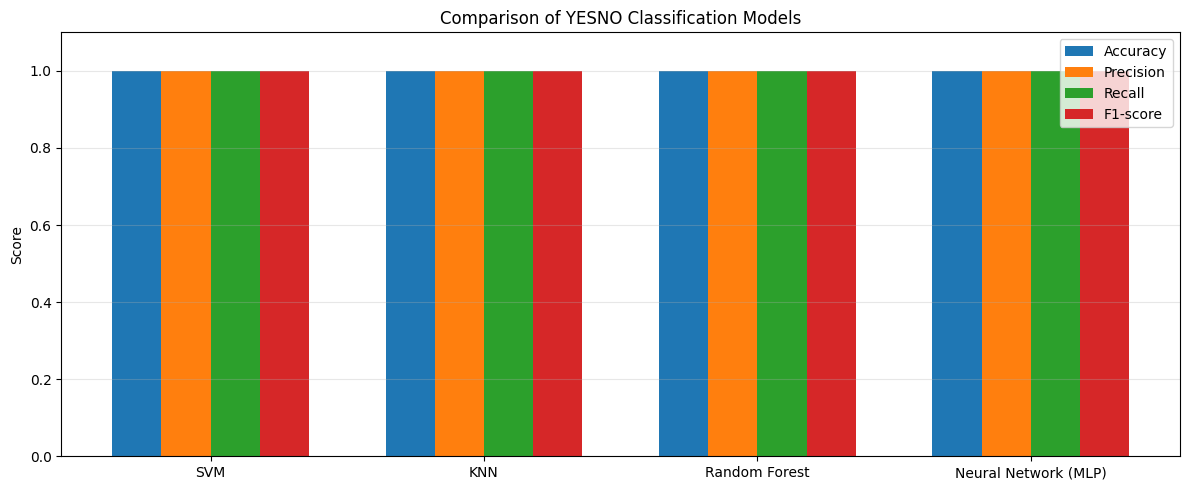

In [33]:

# Step 16: Compare All Four Classifiers

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

comparison_df = pd.DataFrame({
    "Classifier": [
        "SVM",
        "KNN",
        "Random Forest",
        "Neural Network (MLP)"
    ],
    "Accuracy": [
        svm_accuracy,
        knn_accuracy,
        rf_accuracy,
        mlp_accuracy
    ],
    "Precision": [
        svm_precision,
        knn_precision,
        rf_precision,
        mlp_precision
    ],
    "Recall": [
        svm_recall,
        knn_recall,
        rf_recall,
        mlp_recall
    ],
    "F1-score": [
        svm_f1,
        knn_f1,
        rf_f1,
        mlp_f1
    ]
})

print("Classification Model Comparison")
print("--------------------------------")
print(comparison_df.to_string(index=False))

# Grouped bar chart
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

x = np.arange(len(comparison_df))
width = 0.18

plt.figure(figsize=(12, 5))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        comparison_df[metric],
        width,
        label=metric
    )

plt.xticks(x, comparison_df["Classifier"])
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("Comparison of YESNO Classification Models")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Step 16: Results and Discussion

Four machine learning classifiers were trained and evaluated using the YESNO speech dataset: Support Vector Machine (SVM), K-Nearest Neighbors (KNN), Random Forest, and Multi-Layer Perceptron (MLP).

The dataset contained 480 word-level speech samples, each represented by 26 MFCC-based features.

The data was divided into 384 training samples and 96 testing samples using a recording-level split to prevent overlap between the original recordings in the two subsets.

All four classifiers achieved an accuracy of 100%, with macro-averaged precision, recall, and F1-score equal to 1.00.

The confusion matrices showed that all 43 No samples and 53 Yes samples were classified correctly by each model.

The comparison chart demonstrates that the four classifiers achieved identical performance on the selected test set.

These results indicate that the MFCC-based features were effective for distinguishing the two speech classes in this experiment. However, the perfect scores should not be interpreted as evidence of universal generalization. Additional validation is needed to assess performance across different recording-level splits.

### Step 17: Group-Based Cross-Validation

To further evaluate the reliability of the classification results, five-fold group-based cross-validation was performed.

The GroupKFold method was selected to ensure that speech segments originating from the same recording were not shared between the training and validation sets within each fold.

The four classifiers were evaluated using the same MFCC feature matrix and group assignments.

Accuracy and macro-averaged F1-score were calculated for each fold, and their mean and standard deviation were used to assess model performance and stability.

This additional evaluation provides a more comprehensive assessment than relying on a single train/test split.

In [34]:

# Step 17: Group-Based Cross-Validation

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, cross_validate

# Use the four previously defined models
models = {
    "SVM": svm_model,
    "KNN": knn_model,
    "Random Forest": rf_model,
    "Neural Network (MLP)": mlp_model
}

# Five-fold group-based cross-validation
cv = GroupKFold(n_splits=5)

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        groups=groups,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        n_jobs=1
    )

    cv_results.append({
        "Classifier": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Std Accuracy": scores["test_accuracy"].std(),
        "Mean F1": scores["test_f1_macro"].mean(),
        "Std F1": scores["test_f1_macro"].std()
    })

cv_df = pd.DataFrame(cv_results)

print("5-Fold Group Cross-Validation Results")
print("-------------------------------------")
print(cv_df.round(4).to_string(index=False))


5-Fold Group Cross-Validation Results
-------------------------------------
          Classifier  Mean Accuracy  Std Accuracy  Mean F1  Std F1
                 SVM         0.9938        0.0125   0.9937  0.0127
                 KNN         0.9938        0.0125   0.9937  0.0127
       Random Forest         0.9938        0.0125   0.9937  0.0127
Neural Network (MLP)         0.9938        0.0125   0.9937  0.0127


### Step 17: Results and Discussion

Five-fold group-based cross-validation was conducted to evaluate the stability of the four classification models.

The GroupKFold method was used to prevent speech segments from the same original recording from appearing in both the training and validation subsets within each fold.

All four classifiers achieved a mean accuracy of approximately 99.38%, with a standard deviation of 1.25 percentage points.

The mean macro F1-score was approximately 99.37%, with a standard deviation of 1.27 percentage points.

The results indicate that SVM, KNN, Random Forest, and MLP achieved similarly high performance across the five recording-level validation folds.

Compared with the 100% accuracy obtained from the initial train/test split, the cross-validation results provide additional evidence of strong classification performance.

However, the experiment is limited to the relatively small YESNO dataset, and further testing on independent recordings would be necessary to assess generalization to broader speech conditions.

## Step 19: Exploratory Feature Selection using RFECV

Recursive Feature Elimination with Cross-Validation (RFECV) was explored to identify a compact subset of the 26 MFCC summary features. A Random Forest estimator and five-fold `GroupKFold` preserve recording-level separation **within each feature-selection fold**. This is an exploratory analysis on the full dataset; the resulting selected features must **not** be evaluated on the original held-out test set as an independent final score without repeating feature selection using training data only.

The previously saved run reported **3 selected features**: `Mean_MFCC_3`, `Mean_MFCC_6`, and `Mean_MFCC_8`. Re-running the code below recomputes the result.

In [ ]:
# Step 19: Exploratory RFECV feature selection (requires Step 10 first)
from sklearn.feature_selection import RFECV
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
import numpy as np

assert X.shape == (480, 26), "Run Step 10 to build the expected feature matrix"
assert len(y) == len(groups) == len(X)

estimator = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rfecv = RFECV(
    estimator=estimator,
    step=1,
    cv=GroupKFold(n_splits=5),
    scoring="accuracy",
    n_jobs=1
)
rfecv.fit(X, y, groups=groups)

feature_names = ([f"Mean_MFCC_{i}" for i in range(13)] +
                 [f"Std_MFCC_{i}" for i in range(13)])
selected_features = [name for name, selected in zip(feature_names, rfecv.support_)
                     if selected]
print("Optimal number of features selected:", rfecv.n_features_)
print("Selected features:", selected_features)


### RFECV: Cross-Validation Accuracy vs. Number of Selected Features

In [ ]:
# Plot RFECV feature selection results
import matplotlib.pyplot as plt
mean_scores = rfecv.cv_results_["mean_test_score"]
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(mean_scores) + 1), mean_scores, marker="o")
plt.xlabel("Number of selected features")
plt.ylabel("Mean group cross-validation accuracy")
plt.title("RFECV Feature Selection – YESNO")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Step 19: Results and Discussion

In the uploaded RFECV experiment, the optimal subset contained **three features** (`Mean_MFCC_3`, `Mean_MFCC_6`, `Mean_MFCC_8`). This indicates that a small subset of the original 26 MFCC summary features may be informative for distinguishing the classes. The RFECV result is exploratory, because the selection was performed on the entire dataset. A fair performance comparison for a feature-selected classifier would require RFECV to be fitted inside each training fold (nested evaluation), without using its validation recordings for feature selection.

## Step 20: Final Conclusion

This mini-project investigated binary speech classification using the YESNO dataset provided through TorchAudio.

The dataset contained 60 audio recordings, with eight spoken words per recording, resulting in 480 word-level speech samples.

An energy-based segmentation approach was used to separate individual words. Initial segmentation produced the expected number of segments in 52 recordings, while the remaining eight recordings required parameter optimization and manual verification.

For each speech segment, 13 MFCC coefficients were extracted. Their means and standard deviations were combined to form a 26-dimensional feature vector.

Four classification models were implemented and evaluated: Support Vector Machine (SVM), K-Nearest Neighbors (KNN), Random Forest, and Multi-Layer Perceptron (MLP).

A recording-level train/test split was applied, resulting in 384 training samples and 96 testing samples. All four classifiers achieved 100% accuracy, precision, recall, and F1-score on the held-out test set.

Furthermore, five-fold group-based cross-validation produced a mean accuracy of approximately 99.38% and a mean macro F1-score of approximately 99.37% for all four classifiers.

These results demonstrate that MFCC-based features, combined with supervised machine learning methods, can effectively distinguish between the two speech classes in the YESNO dataset.

**Limitations:** The dataset is relatively small, and the experiments were conducted using recordings from a limited speech domain. Therefore, the results should not be assumed to generalize to larger datasets, different speakers, or noisy real-world environments without further evaluation.

**Future Work:** Future experiments could investigate additional acoustic features, larger speech datasets, noise robustness, and more advanced deep learning architectures.